
QUESTION 1: TEXT PREPROCESSING AND TOKENIZATION

Original Paragraph:

Artificial intelligence is transforming the way people interact
with technology. Intelligent systems are helping doctors detect
diseases and improve healthcare services. Students are using
AI-powered tools to understand complex concepts. Businesses
are developing innovative solutions through machine learning.
I believe technology's greatest strength is its ability to
solve real-world problems. Responsible development of artificial
intelligence can create a better future for everyone.


Lowercase Text Without Punctuation:
artificial intelligence is transforming the way people interact with technology intelligent systems are helping doctors detect diseases and improve healthcare services students are using ai powered tools to understand complex concepts businesses are developing innovative solutions through machine learning i believe technology s greatest strength is its ability to solve real world problems responsibl

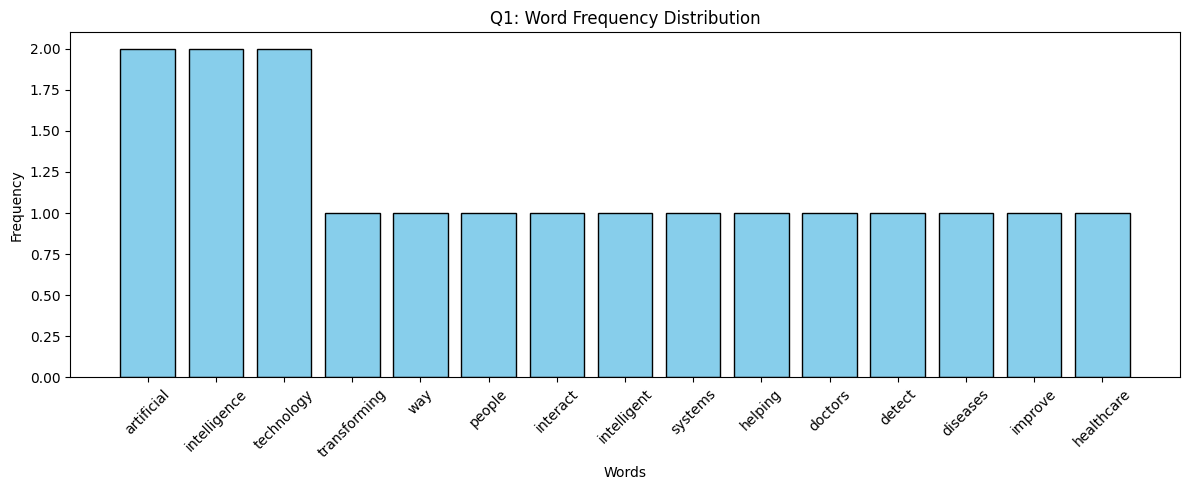


QUESTION 2: STEMMING AND LEMMATIZATION

Alphabetic Words:
['artificial', 'intelligence', 'is', 'transforming', 'the', 'way', 'people', 'interact', 'with', 'technology', 'intelligent', 'systems', 'are', 'helping', 'doctors', 'detect', 'diseases', 'and', 'improve', 'healthcare', 'services', 'students', 'are', 'using', 'ai', 'powered', 'tools', 'to', 'understand', 'complex', 'concepts', 'businesses', 'are', 'developing', 'innovative', 'solutions', 'through', 'machine', 'learning', 'i', 'believe', 'technology', 's', 'greatest', 'strength', 'is', 'its', 'ability', 'to', 'solve', 'real', 'world', 'problems', 'responsible', 'development', 'of', 'artificial', 'intelligence', 'can', 'create', 'a', 'better', 'future', 'for', 'everyone']

After Stopword Removal:
['artificial', 'intelligence', 'transforming', 'way', 'people', 'interact', 'technology', 'intelligent', 'systems', 'helping', 'doctors', 'detect', 'diseases', 'improve', 'healthcare', 'services', 'students', 'using', 'ai', 'powered', 't

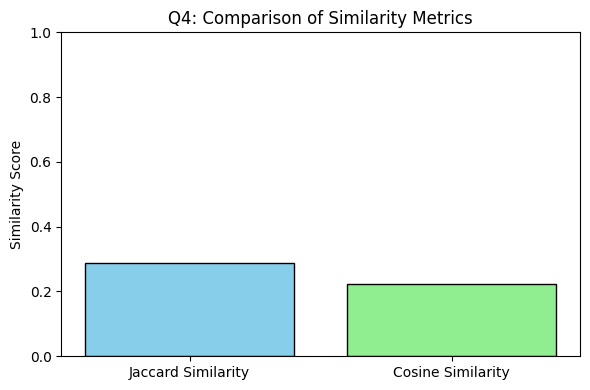


QUESTION 5: SENTIMENT ANALYSIS

Review 1: These headphones are excellent and provide amazing sound quality.
Polarity: 0.6667
Subjectivity: 0.7667
Sentiment: Positive

Review 2: I love the comfortable design and fantastic battery life.
Polarity: 0.4333
Subjectivity: 0.7667
Sentiment: Positive

Review 3: The product is disappointing and the sound quality is terrible.
Polarity: -0.4000
Subjectivity: 0.7000
Sentiment: Negative

Review 4: The headphones come with a charging cable and a storage case.
Polarity: 0.0000
Subjectivity: 0.0000
Sentiment: Neutral

Review 5: Wonderful product with great noise cancellation and clear audio.
Polarity: 0.6333
Subjectivity: 0.7111
Sentiment: Positive

Review 6: The battery performance is poor and the design is uncomfortable.
Polarity: -0.4500
Subjectivity: 0.8000
Sentiment: Negative

Interpretation:
Polarity ranges from -1 to +1.
Negative values represent negative sentiment.
Positive values represent positive sentiment.
Zero represents neutral sentiment

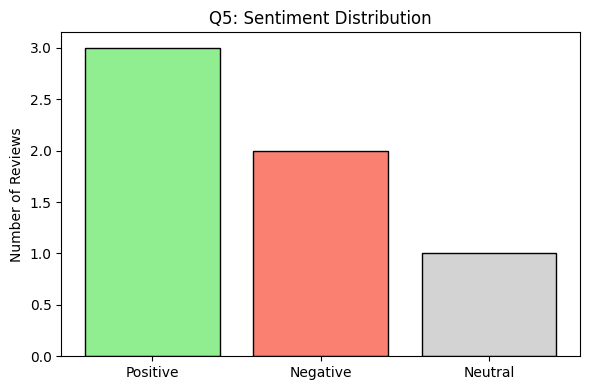

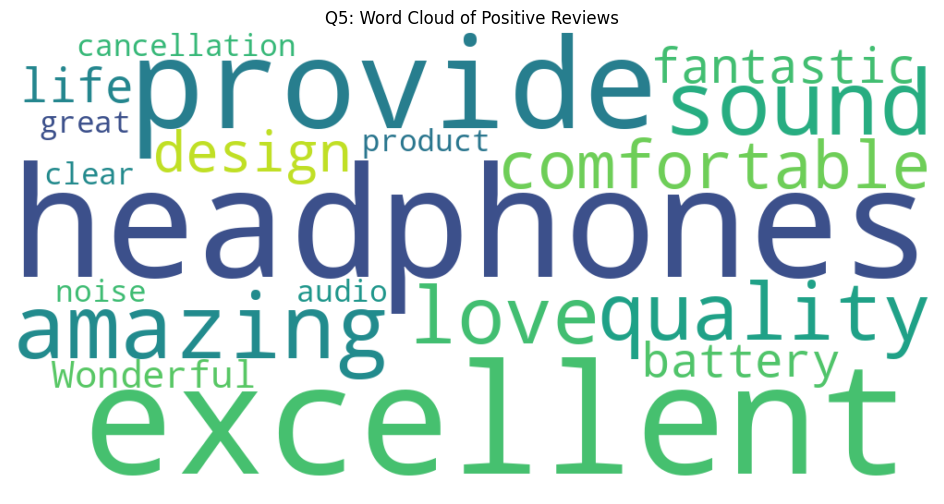


QUESTION 6: TEXT GENERATION USING LSTM

Training Paragraph:

Technology is changing the world through innovation and creativity.
Artificial intelligence helps people solve complex problems.
Machine learning allows computers to learn from data and experience.
Technology improves healthcare education communication and transportation.
Intelligent systems help doctors identify diseases and provide better treatment.
Students use digital tools to explore new ideas and develop skills.
Businesses use technology to improve productivity and customer experience.
Artificial intelligence creates opportunities for scientific research and discovery.
Responsible technology development ensures privacy safety and fairness.
Technology connects people across the world and encourages collaboration.
The future of technology depends on human creativity and responsible innovation.

Training Word Count: 100

Vocabulary Size: 74

Word Index:
{'and': 1, 'technology': 2, 'the': 3, 'to': 4, 'world': 5, 'innovatio

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 10, 32)         │         2,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 74)             │         4,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,010 (125.04 KB)

 Trainable params: 32,010 (125.04 KB)

 Non-trainable params: 0 (0.00 B)


Training the LSTM Model...

Model Training Completed!
Final Training Accuracy: 96.63%
Final Training Loss: 0.1742


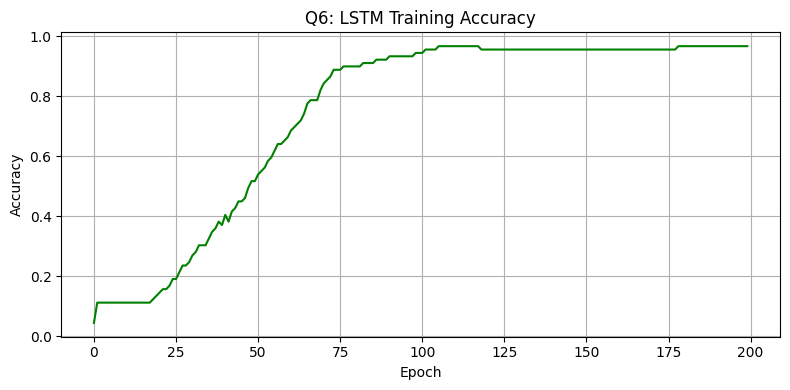

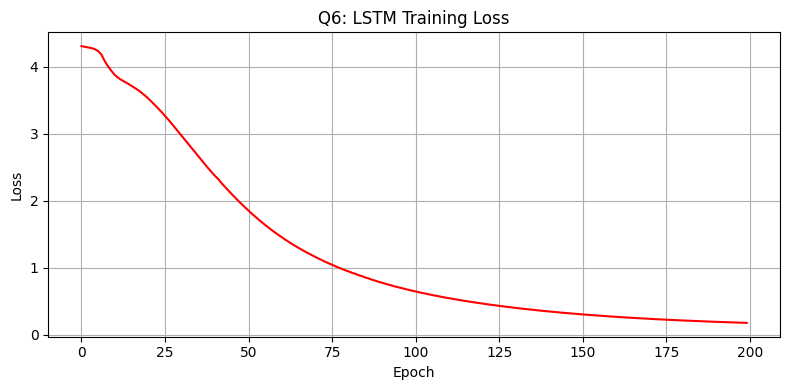


Generated Text:

Line 1:
Technology connects people across the world and encourages collaboration collaboration collaboration innovation innovation.

Line 2:
Artificial intelligence creates opportunities for scientific research and discovery discovery and treatment treatment.

Line 3:
Students use digital tools to explore new ideas and develop skills skills skills.

Interpretation:
The LSTM model learns word sequences from the training paragraph.
It predicts the next word based on the preceding words.
The predicted word is appended to the input, and the process
is repeated to generate new text.

Since the training dataset contains only approximately 100 words,
the model may memorize phrases or generate repetitive sentences.
A larger training dataset would improve text generation quality.




In [1]:
# ============================================================
# UCS420 - Cognitive Computing
# Lab Assignment 8
# NLP using Python-II
# ============================================================

# Install required libraries
!pip -q install nltk textblob wordcloud scikit-learn

# Import libraries
import re
import nltk
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist
from nltk.stem import PorterStemmer, WordNetLemmatizer

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

from textblob import TextBlob
from wordcloud import WordCloud

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense

# Download NLTK resources
for resource in ['punkt', 'punkt_tab', 'stopwords', 'wordnet', 'omw-1.4']:
    nltk.download(resource, quiet=True)

stop_words = set(stopwords.words('english'))

# ============================================================
# QUESTION 1: Text Preprocessing and Tokenization
# ============================================================

print("\n" + "="*65)
print("QUESTION 1: TEXT PREPROCESSING AND TOKENIZATION")
print("="*65)

paragraph = """
Artificial intelligence is transforming the way people interact
with technology. Intelligent systems are helping doctors detect
diseases and improve healthcare services. Students are using
AI-powered tools to understand complex concepts. Businesses
are developing innovative solutions through machine learning.
I believe technology's greatest strength is its ability to
solve real-world problems. Responsible development of artificial
intelligence can create a better future for everyone.
"""

print("\nOriginal Paragraph:")
print(paragraph)

# 1. Convert to lowercase and remove punctuation
clean_text = re.sub(r'[^\w\s]', ' ', paragraph.lower())
clean_text = re.sub(r'\s+', ' ', clean_text).strip()

print("\nLowercase Text Without Punctuation:")
print(clean_text)

# 2. Word and sentence tokenization
words = word_tokenize(clean_text)
sentences = sent_tokenize(paragraph.strip())

print("\nWord Tokens:")
print(words)

print("\nSentence Tokens:")
for i, sentence in enumerate(sentences, 1):
    print(f"{i}. {sentence}")

# 3. Compare split() and word_tokenize()
# Original paragraph is used to demonstrate punctuation handling
split_tokens = paragraph.split()
nltk_tokens = word_tokenize(paragraph)

print("\nTokens using split():")
print(split_tokens)

print("\nTokens using word_tokenize():")
print(nltk_tokens)

print("\nNumber of split() tokens:", len(split_tokens))
print("Number of NLTK tokens:", len(nltk_tokens))

print("""
Comparison:
Python split() separates words based on whitespace and keeps
punctuation attached to words.
NLTK word_tokenize() handles punctuation and contractions
more intelligently.
""")

# 4. Remove stopwords
filtered_words = [word for word in words
                  if word not in stop_words]

print("\nWords After Stopword Removal:")
print(filtered_words)

# 5. Word frequency distribution
frequency = FreqDist(filtered_words)

print("\nWord Frequency Distribution:")
for word, count in frequency.most_common():
    print(f"{word}: {count}")

# Plot frequency distribution
top_words = frequency.most_common(15)

plt.figure(figsize=(12, 5))
plt.bar(
    [word for word, count in top_words],
    [count for word, count in top_words],
    color='skyblue',
    edgecolor='black'
)
plt.title("Q1: Word Frequency Distribution")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# ============================================================
# QUESTION 2: Stemming and Lemmatization
# ============================================================

print("\n" + "="*65)
print("QUESTION 2: STEMMING AND LEMMATIZATION")
print("="*65)

# 1. Extract alphabetic words
alphabetic_words = re.findall(r'\b[a-zA-Z]+\b', paragraph.lower())

print("\nAlphabetic Words:")
print(alphabetic_words)

# 2. Remove stopwords
filtered = [word for word in alphabetic_words
            if word not in stop_words]

print("\nAfter Stopword Removal:")
print(filtered)

# 3. Stemming
stemmer = PorterStemmer()
stemmed_words = [stemmer.stem(word) for word in filtered]

print("\nStemmed Words:")
print(stemmed_words)

# 4. Lemmatization
lemmatizer = WordNetLemmatizer()

lemmatized_words = [
    lemmatizer.lemmatize(word) for word in filtered
]

print("\nLemmatized Words:")
print(lemmatized_words)

# 5. Comparison
print("\nComparison Table:")
print(f"{'Original Word':<22}{'Stemmed Word':<22}{'Lemmatized Word':<22}")
print("-"*66)

for original, stemmed, lemma in zip(
    filtered, stemmed_words, lemmatized_words
):
    print(f"{original:<22}{stemmed:<22}{lemma:<22}")

print("""
Interpretation:
Stemming removes prefixes or suffixes to obtain a root form,
which may not be a valid dictionary word.

Lemmatization converts words into meaningful dictionary forms.
WordNetLemmatizer uses noun-based lemmatization by default.

Stemming is preferred for fast information retrieval and
search engines.

Lemmatization is preferred for applications requiring meaningful
words, such as chatbots, translation and text analysis.
""")


# ============================================================
# QUESTION 3: Bag of Words and TF-IDF
# ============================================================

print("\n" + "="*65)
print("QUESTION 3: BAG OF WORDS AND TF-IDF")
print("="*65)

texts = [
    "Artificial intelligence improves healthcare through intelligent diagnosis.",
    "Electric vehicles reduce pollution and support sustainable transportation.",
    "Cybersecurity protects digital systems from malicious cyber attacks."
]

print("\nOriginal Texts:")
for i, text in enumerate(texts, 1):
    print(f"Text {i}: {text}")

# 1. Bag of Words
count_vectorizer = CountVectorizer(stop_words='english')
bow_matrix = count_vectorizer.fit_transform(texts)

print("\nBag of Words Vocabulary:")
print(count_vectorizer.get_feature_names_out())

print("\nBag of Words Matrix:")
print(bow_matrix.toarray())

# 2. TF-IDF
tfidf_vectorizer = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf_vectorizer.fit_transform(texts)

feature_names = tfidf_vectorizer.get_feature_names_out()

print("\nTF-IDF Vocabulary:")
print(feature_names)

print("\nTF-IDF Matrix:")
print(np.round(tfidf_matrix.toarray(), 4))

# 3. Top 3 keywords
print("\nTop 3 Keywords From Each Text:")

for i, row in enumerate(tfidf_matrix.toarray()):

    sorted_indices = np.argsort(row)[::-1]
    top_indices = [idx for idx in sorted_indices if row[idx] > 0][:3]

    print(f"\nText {i+1}:")

    for index in top_indices:
        print(f"{feature_names[index]}: {row[index]:.4f}")

print("""
Interpretation:
Bag of Words represents documents using word occurrence counts.

TF-IDF assigns importance to words based on their frequency
within a document and rarity across documents.

The top keywords highlight important terms in each text.
When several words have equal TF-IDF scores, any of those
equally ranked words may appear among the top three.
""")


# ============================================================
# QUESTION 4: Jaccard and Cosine Similarity
# ============================================================

print("\n" + "="*65)
print("QUESTION 4: TEXT SIMILARITY")
print("="*65)

text1 = """
Artificial intelligence uses data to develop intelligent systems.
AI helps businesses automate complex tasks.
Machine learning improves decision making.
AI technology provides innovative digital solutions.
Intelligent systems improve efficiency and security.
"""

text2 = """
Blockchain technology provides secure digital transactions.
Blockchain uses distributed systems to store data.
It improves transparency and security.
Businesses use blockchain to develop reliable digital solutions.
Blockchain technology reduces dependence on central authorities.
"""

print("\nText 1 - Artificial Intelligence:")
print(text1)

print("\nText 2 - Blockchain:")
print(text2)

# 1. Preprocessing and tokenization
def preprocess(text):
    text = text.lower()
    tokens = re.findall(r'\b[a-z]+\b', text)
    return [word for word in tokens if word not in stop_words]

tokens1 = preprocess(text1)
tokens2 = preprocess(text2)

print("\nPreprocessed Text 1:")
print(tokens1)

print("\nPreprocessed Text 2:")
print(tokens2)

# 2(a). Jaccard Similarity
set1 = set(tokens1)
set2 = set(tokens2)

intersection = set1.intersection(set2)
union = set1.union(set2)

jaccard_similarity = len(intersection) / len(union)

print("\nCommon Words:")
print(sorted(intersection))

print("\nNumber of Common Words:", len(intersection))
print("Number of Unique Words in Union:", len(union))

print(f"\nJaccard Similarity: {jaccard_similarity:.4f}")
print(f"Jaccard Similarity Percentage: {jaccard_similarity*100:.2f}%")

# 2(b). Cosine Similarity
processed_texts = [
    ' '.join(tokens1),
    ' '.join(tokens2)
]

vectorizer = TfidfVectorizer()
vectors = vectorizer.fit_transform(processed_texts)

cosine_score = cosine_similarity(vectors[0], vectors[1])[0][0]

print(f"\nCosine Similarity: {cosine_score:.4f}")
print(f"Cosine Similarity Percentage: {cosine_score*100:.2f}%")

# 2(c). Analysis
print("""
Analysis:
Jaccard Similarity measures the overlap between unique words
and ignores word frequency.

Cosine Similarity measures the similarity between TF-IDF
vectors and considers the importance and frequency of words.

Both technologies share terms related to digital systems,
businesses, data and security.

Cosine Similarity provides more detailed insights in this case
because it considers weighted word importance rather than
only the presence or absence of words.

Neither metric directly understands the semantic meaning
of the technologies.
""")

plt.figure(figsize=(6, 4))
plt.bar(
    ['Jaccard Similarity', 'Cosine Similarity'],
    [jaccard_similarity, cosine_score],
    color=['skyblue', 'lightgreen'],
    edgecolor='black'
)
plt.ylim(0, 1)
plt.ylabel("Similarity Score")
plt.title("Q4: Comparison of Similarity Metrics")
plt.tight_layout()
plt.show()


# ============================================================
# QUESTION 5: Sentiment Analysis and Word Cloud
# ============================================================

print("\n" + "="*65)
print("QUESTION 5: SENTIMENT ANALYSIS")
print("="*65)

# Product reviews for wireless headphones
reviews = [
    "These headphones are excellent and provide amazing sound quality.",
    "I love the comfortable design and fantastic battery life.",
    "The product is disappointing and the sound quality is terrible.",
    "The headphones come with a charging cable and a storage case.",
    "Wonderful product with great noise cancellation and clear audio.",
    "The battery performance is poor and the design is uncomfortable."
]

positive_reviews = []

sentiment_counts = {
    'Positive': 0,
    'Negative': 0,
    'Neutral': 0
}

# 1. Polarity and subjectivity
# 2. Sentiment classification
for i, review in enumerate(reviews, 1):

    blob = TextBlob(review)

    polarity = blob.sentiment.polarity
    subjectivity = blob.sentiment.subjectivity

    if polarity > 0:
        sentiment = "Positive"
        positive_reviews.append(review)

    elif polarity < 0:
        sentiment = "Negative"

    else:
        sentiment = "Neutral"

    sentiment_counts[sentiment] += 1

    print(f"\nReview {i}: {review}")
    print(f"Polarity: {polarity:.4f}")
    print(f"Subjectivity: {subjectivity:.4f}")
    print(f"Sentiment: {sentiment}")

print("""
Interpretation:
Polarity ranges from -1 to +1.
Negative values represent negative sentiment.
Positive values represent positive sentiment.
Zero represents neutral sentiment.

Subjectivity ranges from 0 to 1.
Values closer to 0 indicate factual or objective statements.
Values closer to 1 indicate personal opinions.
""")

print("\nSentiment Distribution:")
for sentiment, count in sentiment_counts.items():
    print(f"{sentiment}: {count}")

# Plot sentiment distribution
plt.figure(figsize=(6, 4))
plt.bar(
    sentiment_counts.keys(),
    sentiment_counts.values(),
    color=['lightgreen', 'salmon', 'lightgray'],
    edgecolor='black'
)
plt.title("Q5: Sentiment Distribution")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

# 3. Word cloud for positive reviews
positive_text = ' '.join(positive_reviews)

if positive_text:

    wordcloud = WordCloud(
        width=1000,
        height=500,
        background_color='white',
        colormap='viridis',
        stopwords=stop_words,
        collocations=False
    ).generate(positive_text)

    plt.figure(figsize=(12, 6))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title("Q5: Word Cloud of Positive Reviews")
    plt.show()

else:
    print("No positive reviews available for the word cloud.")


# ============================================================
# QUESTION 6: Text Generation Using LSTM
# ============================================================

print("\n" + "="*65)
print("QUESTION 6: TEXT GENERATION USING LSTM")
print("="*65)

tf.keras.utils.set_random_seed(42)

# Training paragraph of approximately 100 words
training_text = """
Technology is changing the world through innovation and creativity.
Artificial intelligence helps people solve complex problems.
Machine learning allows computers to learn from data and experience.
Technology improves healthcare education communication and transportation.
Intelligent systems help doctors identify diseases and provide better treatment.
Students use digital tools to explore new ideas and develop skills.
Businesses use technology to improve productivity and customer experience.
Artificial intelligence creates opportunities for scientific research and discovery.
Responsible technology development ensures privacy safety and fairness.
Technology connects people across the world and encourages collaboration.
The future of technology depends on human creativity and responsible innovation.
"""

print("\nTraining Paragraph:")
print(training_text)

print("Training Word Count:", len(training_text.split()))

# 1. Tokenization using Keras Tokenizer
tokenizer = Tokenizer()
tokenizer.fit_on_texts([training_text])

total_words = len(tokenizer.word_index) + 1

print("\nVocabulary Size:", total_words)

print("\nWord Index:")
print(tokenizer.word_index)

# 2. Create input sequences
input_sequences = []

for line in training_text.strip().split('\n'):

    token_list = tokenizer.texts_to_sequences([line])[0]

    for i in range(1, len(token_list)):
        n_gram_sequence = token_list[:i+1]
        input_sequences.append(n_gram_sequence)

# Padding sequences
max_sequence_len = max(len(seq) for seq in input_sequences)

input_sequences = np.array(
    pad_sequences(
        input_sequences,
        maxlen=max_sequence_len,
        padding='pre'
    )
)

# Split into input and target
X = input_sequences[:, :-1]
y = input_sequences[:, -1]

print("\nInput Shape:", X.shape)
print("Target Shape:", y.shape)
print("Maximum Sequence Length:", max_sequence_len)

# Build LSTM model
model = Sequential([
    Input(shape=(max_sequence_len - 1,)),
    Embedding(total_words, 32, mask_zero=True),
    LSTM(64),
    Dense(total_words, activation='softmax')
])

model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

print("\nLSTM Model Architecture:")
model.summary()

# 3. Train model
print("\nTraining the LSTM Model...")

history = model.fit(
    X,
    y,
    epochs=200,
    batch_size=16,
    verbose=0
)

print("\nModel Training Completed!")

print(f"Final Training Accuracy: {history.history['accuracy'][-1]*100:.2f}%")
print(f"Final Training Loss: {history.history['loss'][-1]:.4f}")

# Plot training accuracy
plt.figure(figsize=(8, 4))
plt.plot(history.history['accuracy'], color='green')
plt.title("Q6: LSTM Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid(True)
plt.tight_layout()
plt.show()

# Plot training loss
plt.figure(figsize=(8, 4))
plt.plot(history.history['loss'], color='red')
plt.title("Q6: LSTM Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.tight_layout()
plt.show()

# Function to generate text
def generate_text(seed_text, next_words=12):

    generated_text = seed_text.lower()

    for _ in range(next_words):

        token_list = tokenizer.texts_to_sequences(
            [generated_text]
        )[0]

        token_list = pad_sequences(
            [token_list],
            maxlen=max_sequence_len - 1,
            padding='pre',
            truncating='pre'
        )

        probabilities = model.predict(token_list, verbose=0)[0]

        # Prevent prediction of padding token
        probabilities[0] = 0

        predicted_index = np.argmax(probabilities)

        predicted_word = tokenizer.index_word.get(
            predicted_index, ''
        )

        if not predicted_word:
            break

        generated_text += " " + predicted_word

    return generated_text.capitalize() + "."

# Generate three new lines using different seed words
print("\nGenerated Text:")

seed_words = [
    "Technology",
    "Artificial",
    "Students"
]

for i, seed in enumerate(seed_words, 1):
    print(f"\nLine {i}:")
    print(generate_text(seed, 12))

print("""
Interpretation:
The LSTM model learns word sequences from the training paragraph.
It predicts the next word based on the preceding words.
The predicted word is appended to the input, and the process
is repeated to generate new text.

Since the training dataset contains only approximately 100 words,
the model may memorize phrases or generate repetitive sentences.
A larger training dataset would improve text generation quality.
""")

print("\n" + "="*65)

print("="*65)